### BRIEF 3 - Titanic : nettoyer, explorer et prédire la survie des passagers avec le Machine Learning

### Exposition interactive sur le naufrage du Titanic et répondre à une question : « Quels facteurs ont réellement influencé les chances de survie des passagers ? »

# 1/ IMPORTATIONS DES BIBLIOTHEQUES ET DES DONNEES

In [38]:
# Import des bibliothèques
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# Import des fonctions de la bibliothèque Scikit-learn.
from sklearn.model_selection import train_test_split                    # Découpage entrainement/test.
from sklearn.linear_model import LogisticRegression                     # Régression logistique
from sklearn.ensemble import RandomForestClassifier                     # Random Forest
from xgboost import XGBClassifier                                       # XGBOOST
from sklearn.metrics import accuracy_score                              # Accuracy
from sklearn.metrics import classification_report                       # Classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay    # Matrice de confusion


# Import du fichier "Train"
from google.colab import files
uploaded = files.upload()
train = pd.read_csv("train.csv")

Saving train.csv to train (3).csv


# 2/ EXPLORATION DES DONNEES (EDA)

## a) Découverte du fichier principal "TRAIN"

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
(array([0, 1]), array([549, 342]))


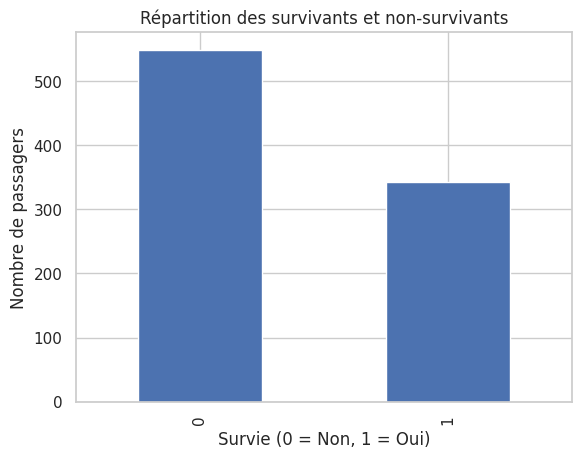

Sex
male      577
female    314
Name: count, dtype: int64
Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64
Moyenne des âges : 29.69911764705882
Médiane des âges : nan


In [39]:
## Dimensions, types des colonnesn, et valeurs manquantes

train.shape                   # le fichier est composé de 891 lignes et 12 colonnes
train.info()                  # On a 2 variables décimales, 5 variables entiers et 5 objet
train.isnull().sum()          # On s'apperçoit qu'il y a des valeurs manquantes dans la variable "Âge", "Cabin", et "Embarked"

train.head()               # Affiche les 5 premières lignes
train.describe()           # Regarde les min, max, moyenne, médiane des variables numériques



## Statistiques descriptives

# Répartition de la variable cible : survie
print(np.unique(train["Survived"], return_counts=True))
train["Survived"].value_counts().plot(kind="bar",title="Répartition des survivants et non-survivants")
plt.xlabel("Survie (0 = Non, 1 = Oui)")
plt.ylabel("Nombre de passagers")
plt.show()
# Sachant qu'on a 891 passengers au total, plus de 500 Passengers n'ont pas survécu, et moins de 350 passengers ont survécu.

# Répartition des autres variables (sex, ticket class, port d'embarquement, âge)
print(train["Sex"].value_counts())
print(train["Pclass"].value_counts())
print(train["Embarked"].value_counts())
print("Moyenne des âges :", np.mean(train["Age"]))
print("Médiane des âges :", np.median(train["Age"]))

Le jeu de données comporte 891 passagers du Titanic, dont 577 hommes et 314 femmes. L'âge moyen des passagers est d'environ 29,4 ans.

Les passagers étaient répartis en trois classes : 491 en première, 216 en deuxième et 184 en troisième classe.

La majorité des passagers (644) ont embarqué à Southampton, contre 168 à Cherbourg et 77 à Queenstown.

Enfin, sur les 891 passagers, plus de 500 n'ont pas survécu, tandis que moins de 350 ont survécu. La majorité des passagers n'a donc pas survécu au naufrage.

## b) Nettoyage des données

In [40]:
### IDENTIFICATION

# DOUBLONS
train.duplicated().sum()          # Il n'y a pas de doublons

# VALEURS MANQUANTES
train.isnull().sum()              # Nombres de valeurs manquantes : Age - 177 N/A ; Cabin - 687 N/A ; Embarked - 2 N/A
na = train.isnull().sum()         # Pour ne prendre que les variables qui contiennent les N/A
print(na[na > 0])



## CREATION D'UNE COPIE DU FICHIER TRAIN AVANT DE MODIFIER LA TABLE "TRAIN"
# Je crée une copie pour ne pas directement modifié l'original
train_clean = train.copy()
print("Copie :", train_clean.shape)
# Je vérifie que le fichier est exactement le même que l'original
train.equals(train_clean)
train_clean.isnull().sum()



## VARIABLE AGE
# Remplacer les âges manquants par la médiane (moins affecté par les valeurs extrêmes)
# Pour éviter de supprimer les passagers concernés, nous avons choisi de remplacer ces valeurs par la médiane des âges.
train_clean["Age"] = train_clean["Age"].fillna(train_clean["Age"].median())


## VARIABLE EMBARKED
# Remplacer les ports manquants par la valeur la plus fréquente
# La colonne Embarked indique le port d'embarquement des passagers. Certaines valeurs sont manquantes.
# Nous avons choisi de remplacer ces valeurs par le mode, c'est-à-dire la valeur la plus fréquente dans cette colonne.
train_clean["Embarked"] = train_clean["Embarked"].fillna(train_clean["Embarked"].mode()[0])


## VARIABLE CABIN
# Je supprime la colonne "Cabine" car elle comporte plus de 75% de valeurs manquantes.
# Nous avons donc choisi de la supprimer afin de limiter les informations manquantes et de simplifier la préparation des données.
train_clean = train_clean.drop(columns=["Cabin"])

Age         177
Cabin       687
Embarked      2
dtype: int64
Copie : (891, 12)


## c) Les graphiques sur la variable "survie" selon chaque variable.

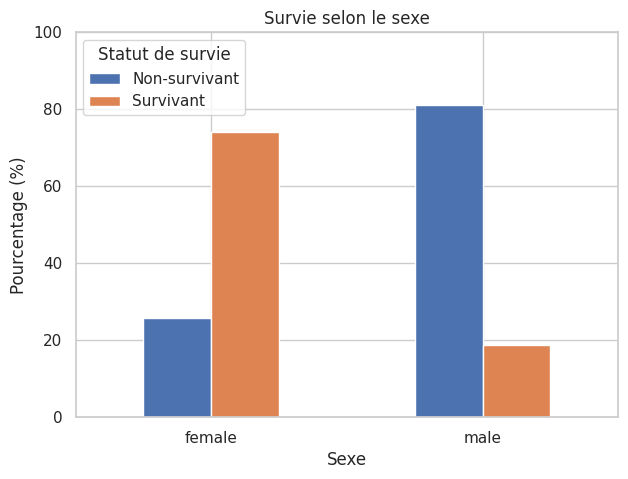

In [41]:
# Survie selon le sex
# Calcul des pourcentages de survie selon le sexe
survie_sexe = pd.crosstab(train_clean["Sex"],train_clean["Survived"],normalize="index") * 100
# Renommer les catégories
survie_sexe = survie_sexe.rename(index={0: "Homme", 1: "Femme"},columns={0: "Non-survivant", 1: "Survivant"})
# Création du graphique
survie_sexe.plot(kind="bar", figsize=(7, 5))
plt.title("Survie selon le sexe")
plt.xlabel("Sexe")
plt.ylabel("Pourcentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Statut de survie")
plt.show()


Dans la représentation graphique de la survie selon le sex, on observe une différence importante entre les hommes et les femmes.
Les femmes ont eu un taux de survie beaucoup plus élevé que les hommes, malgré leur nombre moins important dans le bateau.

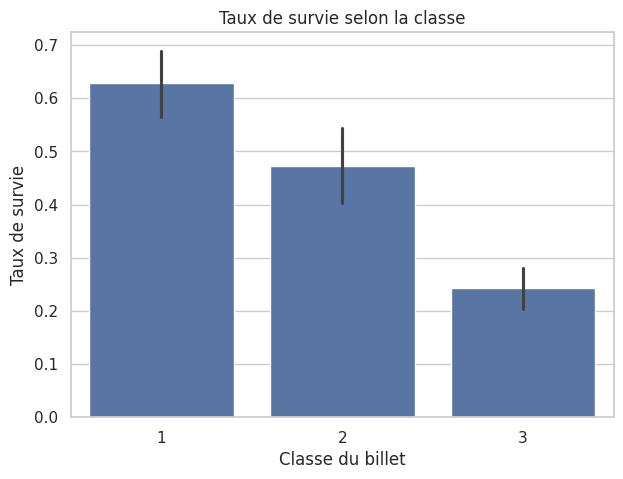

In [42]:
# Survie selon la classe du billet
pd.crosstab(train_clean["Pclass"],train_clean["Survived"],normalize="index") * 100
# Barplot
plt.figure(figsize=(7, 5))
sns.barplot(data=train_clean,x="Pclass",y="Survived")
plt.title("Taux de survie selon la classe")
plt.xlabel("Classe du billet")
plt.ylabel("Taux de survie")
plt.show()

Dans la représentation graphique de la survie selon la classe du billet, on observe que plus de 60% des survivants sont des passengers de classe 1. 40% des passengers de la classe 2 ont survécu. Et moins de 30% des passengers de classe 3 ont survécu.

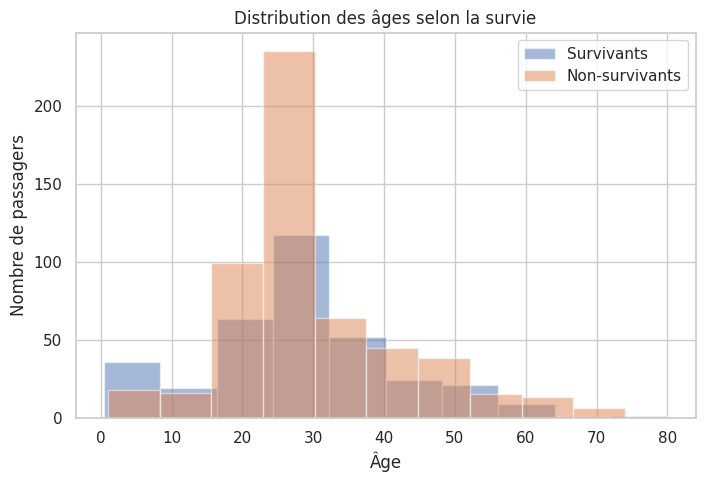

In [43]:
# Survie selon l'âge
train_clean.groupby("Survived")["Age"].mean()
# Histogramme
plt.figure(figsize=(8, 5))
plt.hist(train_clean[train_clean["Survived"] == 1]["Age"],alpha=0.5, label="Survivants")
plt.hist(train_clean[train_clean["Survived"] == 0]["Age"],alpha=0.5, label="Non-survivants")
plt.title("Distribution des âges selon la survie")
plt.xlabel("Âge")
plt.ylabel("Nombre de passagers")
plt.legend()
plt.show()

Dans la représentation graphique de la survie selon l'âge moyen,

on observe que la majorité des passagers âgés de 20 à 30 ans n'ont pas survécu au naufrage, avec plus de 200 décès dans cette tranche d'âge. La majorité de ceux qui ont survécu sont également dans cette tranche d'âge mais entre 25 et 35.

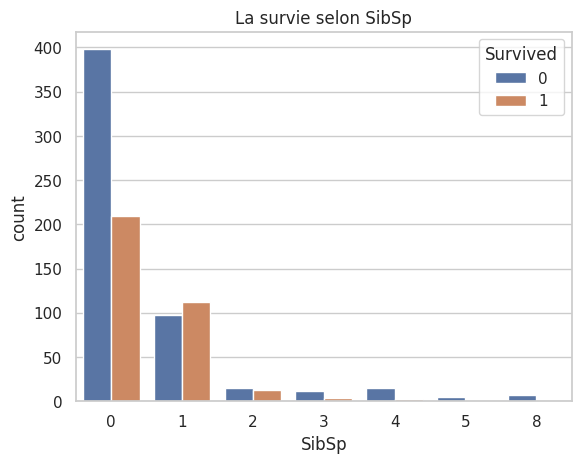

In [44]:
# La survie selon le nombre de frères, sœurs ou conjoints (SibSp)
sns.countplot(data=train_clean, x="SibSp", hue="Survived")
plt.title("La survie selon SibSp")
plt.show()

Dans la représentation graphique de la survie selon SibSp,

on observe que les passagers voyageant avec un ou deux frères, sœurs ou conjoints ont eu davantage de chances de survivre. Le taux de survie diminue lorsque le nombre de personnes accompagnantes augmente.

En effet, on oberve que la majorité des voyageurs qui n'ont pas survécu sont ceux voyageant seul.

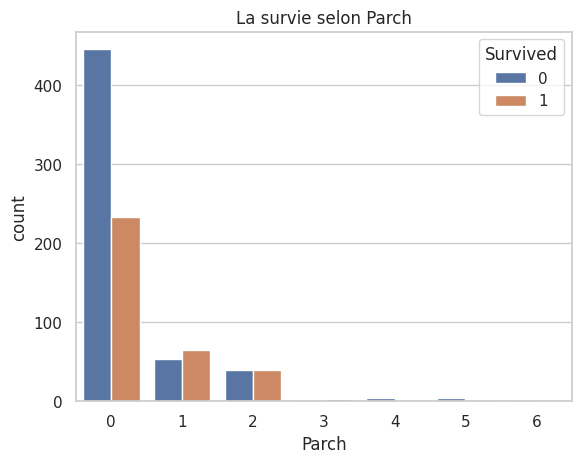

In [45]:
# La survie selon le nombre de parents ou enfants (Parch)
sns.countplot(data=train_clean, x="Parch", hue="Survived")
plt.title("La survie selon Parch")
plt.show()

Dans la représentation graphique de la survie selon Parch,

on observe à peu près les mêmes résultats que le graphique précédent. Les passagers voyageant avec un ou deux enfants ou parents ont eu davantage de chances de survivre.

La majorité des voyageurs qui n'ont pas survécu sont ceux voyageant seul.

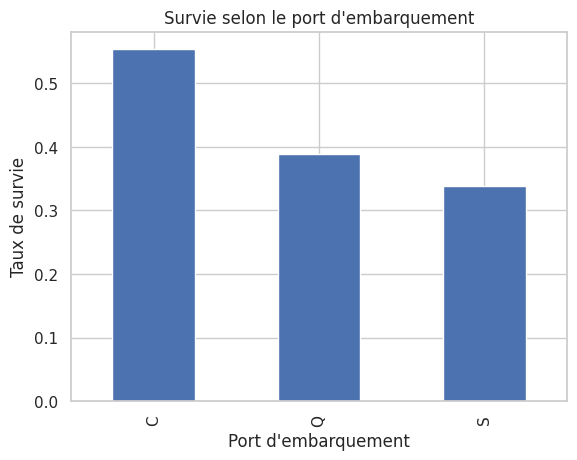

In [46]:
# Survie selon le port d'embarquement
train_clean.groupby("Embarked")["Survived"].mean().plot(kind="bar")
plt.title("Survie selon le port d'embarquement")
plt.xlabel("Port d'embarquement")
plt.ylabel("Taux de survie")
plt.show()

Dans la représentation graphique de la survie selon Embarked,

on observe que les passagers ayant embarqué à Cherbourg ont eu le taux de survie le plus élevé (environ 55 %), suivis de ceux de Queenstown (environ 39 %) et de Southampton (environ 32 %). Le port d'embarquement semble donc être associé aux chances de survie des passagers.

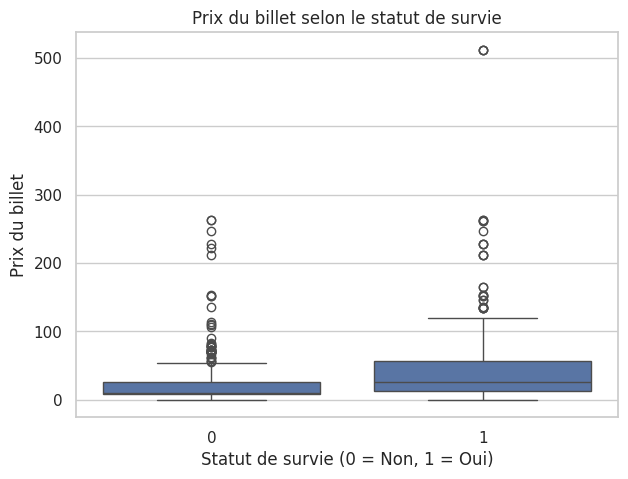

In [47]:
# Prix du billet selon la survie
plt.figure(figsize=(7, 5))
sns.boxplot(data=train_clean, x="Survived", y="Fare")
plt.title("Prix du billet selon le statut de survie")
plt.xlabel("Statut de survie (0 = Non, 1 = Oui)")
plt.ylabel("Prix du billet")
plt.show()

Dans la représentation du prix du billet selon le statut de survie, on observe que les passagers ayant survécu ont généralement payé des billets plus chers que ceux qui n'ont pas survécu.

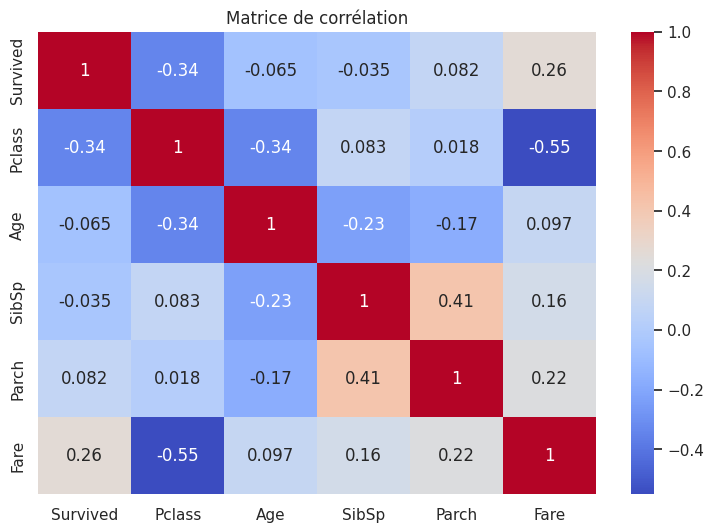

In [48]:
# Corrélations entre variables numériques
plt.figure(figsize=(9, 6))
correlation = (train_clean.drop(columns=["PassengerId"], errors="ignore").select_dtypes(include="number").corr())
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

Dans la matrice de corrélation, on observe que la classe du billet (Pclass) est la variable la plus liée à la survie, avec une corrélation négative de -0,34. Le prix du billet (Fare) présente également une relation positive avec la survie (0,26).

Les autres variables présentent des corrélations très faibles avec la survie.

## d) Feature Engineering

In [49]:
## CREATION DE LA VARIABLE "TITRE",
# Extraire le titre depuis la colonne Name
train_clean["Titre"] = train["Name"].str.extract(r",\s*([^.]*)\.")

# On regroupe les valeurs de titre en 5 catégories : Mr, Miss, Mrs, Master, Rare
# Car certaines valeurs peuvent être rassemblés et ont la même signification.
titre_mapping = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
train_clean["Titre"] = train_clean["Titre"].replace(titre_mapping)
# Garde les titres les plus fréquents
common_titles = ["Mr", "Mrs", "Miss", "Master"]
# Regroupe tous les autres titres dans Rare
train_clean["Titre"] = train_clean["Titre"].where(train_clean["Titre"].isin(common_titles),"Rare")
# Affiche les titres et leur fréquence
print(train_clean["Titre"].value_counts())



## CREATION DE LA VARIABLE "TAILLE DE LA FAMILLE"
# Calcule la taille de la famille
train_clean["TailleFamille"] = (train_clean["SibSp"] + train_clean["Parch"] + 1)
# Affiche quelques résultats
print(train_clean[["SibSp", "Parch", "TailleFamille"]].head())



## CREATION DE LA VARIABLE "PASSAGERS VOYAGEANT SEUL" (O : non et 1 : oui)
# Identifie les passagers voyageant seuls
train_clean["V_Seul"] = (train_clean["TailleFamille"] == 1).astype(int)
# Affiche le nombre de passagers seuls et accompagnés
print(train_clean["V_Seul"].value_counts())
# Vérifie quelques lignes
print(train_clean[["TailleFamille", "V_Seul"]].head())

Titre
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64
   SibSp  Parch  TailleFamille
0      1      0              2
1      1      0              2
2      0      0              1
3      1      0              2
4      0      0              1
V_Seul
1    537
0    354
Name: count, dtype: int64
   TailleFamille  V_Seul
0              2       0
1              2       0
2              1       1
3              2       0
4              1       1


# 3/ LA MODELISATION

## a) Preparation des variables pour la modelisation

In [50]:
# Encodage des variables Sex et Embarked
train_clean["Sex"] = train_clean["Sex"].map({"male": 0,"female": 1})
# Pour le titre et embarked, on doit le mettre en entier (categorie) pour la modélisation.
train_clean = pd.get_dummies(train_clean, columns=["Embarked", "Titre"], dtype=int)

# On enlève les colonnes "Name", "Ticket", et "PassengerId" car on en a pas besoin pour la modélisation
train_clean = train_clean.drop(columns=["Name", "Ticket", "PassengerId"],errors="ignore")
train_clean.head() # Pour vérifier mes variables

# On sépare la base "train" en deux partie x et y pour la modélisation.
# X = toutes les informations utilisées pour prédire la survie (âge, sexe, classe, prix du billet, etc.).
# y = la réponse que le modèle doit apprendre à prédire (Survived).
y = train_clean["Survived"]
X = train_clean.drop(columns=["Survived"])

In [51]:
# Separation des données en données d'entrainement et de test.
# Pour cela : Import de toutes les fonctions de la bibliothèque Scikit-learn. (Voir dans la partie 1 - Importation)

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Données d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)
print(X_train.dtypes)

# X	               les variables explicatives (Age, Sex, Fare...)
# y	               la variable à prédire (Survived)
# X_train	         les données pour entraîner le modèle
# X_test	         les données pour tester le modèle
# y_train	         les réponses pour entraîner le modèle
# y_test	         les vraies réponses pour vérifier les prédictions
# test_size=0.2	   20 % des données seront réservées au test
# random_state=42	 Permet de reproduire la même séparation
# stratify=y	     Conserve approximativement la même proportion de survivants dans les deux groupes

Données d'entraînement : (712, 16)
Données de test : (179, 16)
Pclass             int64
Sex                int64
Age              float64
SibSp              int64
Parch              int64
Fare             float64
TailleFamille      int64
V_Seul             int64
Embarked_C         int64
Embarked_Q         int64
Embarked_S         int64
Titre_Master       int64
Titre_Miss         int64
Titre_Mr           int64
Titre_Mrs          int64
Titre_Rare         int64
dtype: object


## b) Modèle : Regression Logistique

[0 0 0 0 1 1 1 0 0 0]
Précision du modèle : 0.8491620111731844
Précision : 84.92 %
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       110
           1       0.83      0.77      0.80        69

    accuracy                           0.85       179
   macro avg       0.84      0.83      0.84       179
weighted avg       0.85      0.85      0.85       179



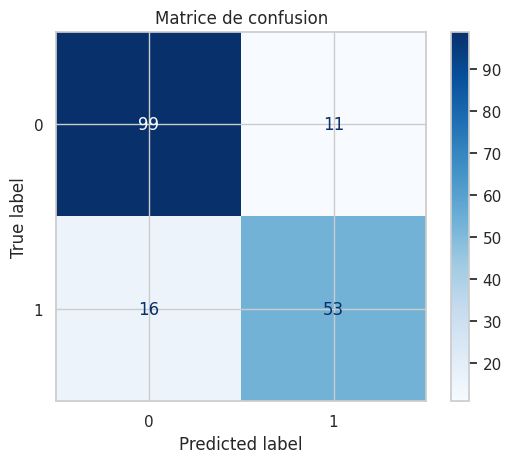

In [52]:
# Pour entrainer le modèle
model = LogisticRegression(max_iter=5000)     # max_iter=5000 permet au modèle d'avoir suffisamment d'itérations pour trouver une solution.
model.fit(X_train, y_train)

# Prédiction du modèle
y_pred = model.predict(X_test)
print(y_pred[:10])               # Seulement les 10 premiers lignes

# Pour évaluer le modèle. Mesurer la précision du modèle (Accuracy)
accuracy = accuracy_score(y_test, y_pred)
print("Précision du modèle :", accuracy)
print("Précision :", round(accuracy * 100, 2), "%")

# Évaluation plus précise du modèle pour voir les bonnes et mauvaises prédictions.
print(classification_report(y_test, y_pred))

# Ce qu'on peut observer
# Pour les non-survivants (0) :
#   - Le modèle identifie correctement 89 % des vrais non-survivants.
#   - Il obtient un F1-score de 85 %.

# Pour les survivants (1) :
#   - Le modèle identifie correctement 68 % des vrais survivants.
#   - Il obtient un F1-score de 73 %.
#   - Il a donc plus de difficultés à identifier les survivants que les non-survivants.

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion")
plt.show()


Le modèle obtient une précision de 84,92 %.

Il prédit mieux les passagers qui n'ont pas survécu (90 %) que ceux qui ont survécu (77 %).

Sur les 179 passagers testés, il a fait 152 bonnes prédictions et 27 erreurs.

## c) Modèle : Random Forest

Accuracy Random Forest : 81.56 %
              precision    recall  f1-score   support

           0       0.85      0.85      0.85       110
           1       0.76      0.75      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179



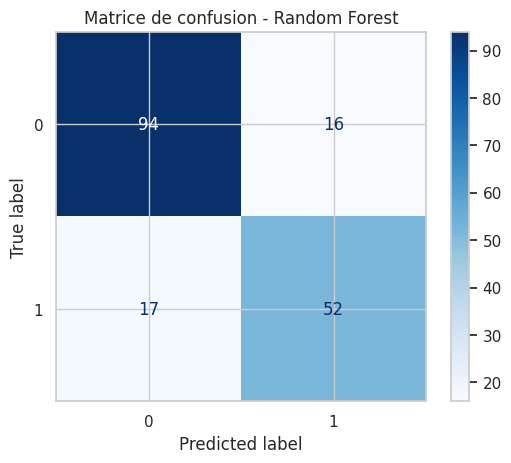

In [53]:
# Création du modèle
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)

# Entraînement du modèle
rf_model.fit(X_train, y_train)

# Prédictions
y_pred_rf = rf_model.predict(X_test)

# Accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Accuracy Random Forest :", round(accuracy_rf * 100, 2), "%")    # Precision : 82,12 %

# Classification
print(classification_report(y_test, y_pred_rf))

# Matrice de confusion
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp.plot(cmap="Blues")
plt.title("Matrice de confusion - Random Forest")
plt.show()

Le modèle Random Forest obtient une précision de 81,56 %.

Il prédit correctement 85 % des non-survivants et 75 % des survivants.

Sur les 179 passagers testés, il a fait 146 bonnes prédictions et 33 erreurs.

Le modèle prédit légèrement mieux les non-survivants que les survivants.

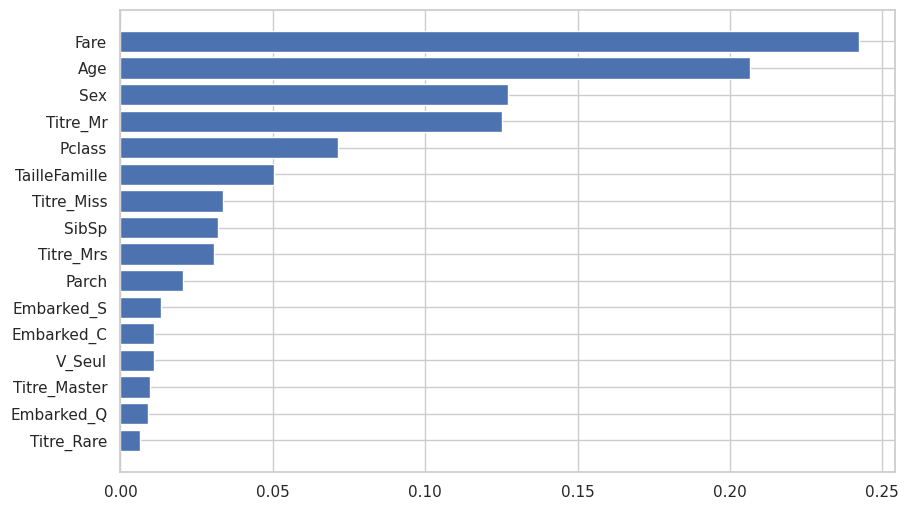

In [54]:
# Récupérer l'importance de chaque variable
importance = pd.DataFrame({"Variable": X_train.columns,"Importance": rf_model.feature_importances_})
# Trier les variables de la plus importante à la moins importante
importance = importance.sort_values(by="Importance",ascending=False)
# Afficher le graphique
plt.figure(figsize=(10, 6))
plt.barh(importance["Variable"], importance["Importance"])
plt.gca().invert_yaxis()

L'analyse de la contribution des variables montre que Fare (prix du billet) est la variable la plus importante pour le modèle, suivie de Age (âge).

On retrouve ensuite Sex (sexe) et Title_Mr, qui ont également joué un rôle important dans les prédictions.

La classe du billet (Pclass) et la taille de la famille (FamilySize) ont aussi contribué aux résultats.

Enfin, la variable Title_Rare est celle qui a le moins d'importance dans le modèle.

Ces résultats montrent que le prix du billet, l'âge et le sexe sont parmi les variables les plus utilisées par le modèle pour prédire la survie des passagers.

## d) Modèle : XGBOOST

Accuracy XGBoost : 81.01 %

Rapport de classification :
              precision    recall  f1-score   support

           0       0.81      0.90      0.85       110
           1       0.81      0.67      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.81      0.81       179



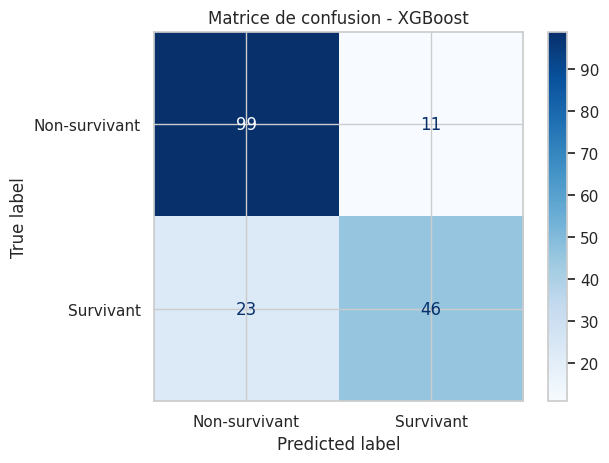

In [55]:
# Création du modèle XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)
# n_estimators=100       : utilise 100 arbres successifs.
# max_depth=3            : limite la profondeur des arbres.
# learning_rate=0.1      : contrôle la vitesse d'apprentissage.
# random_state=42        : permet de reproduire les résultats.
# eval_metric="logloss"  : définit une mesure de l'erreur utilisée pendant l'apprentissage.

# Entraînement du modèle
xgb_model.fit(X_train, y_train)

# Prédictions
y_pred_xgb = xgb_model.predict(X_test)

# Calcul de la précision globale
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print("Accuracy XGBoost :", round(accuracy_xgb * 100, 2), "%")

# Rapport de classification
print("\nRapport de classification :")
print(classification_report(y_test, y_pred_xgb))

# Matrice de confusion
# Calcul de la matrice de confusion
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

# Affichage
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Non-survivant", "Survivant"]
)

disp.plot(cmap="Blues")
plt.title("Matrice de confusion - XGBoost")
plt.show()

Le modèle XGBoost obtient une précision de 81,01 %.

Il prédit correctement 90 % des non-survivants et 67 % des survivants.

Sur les 179 passagers testés, le modèle a correctement identifié 99 non-survivants et 46 survivants. Il a fait 34 erreurs.

Il identifie donc mieux les passagers qui n'ont pas survécu que ceux qui ont survécu.

## e) Comparaison des trois modèles de classification

In [56]:
comparaison = pd.DataFrame({
    "Modèle": [
        "Régression logistique",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ]
})

# Trier les modèles du meilleur au moins performant
comparaison = comparaison.sort_values(
    by="Accuracy (%)",
    ascending=False
)

print(comparaison)

                  Modèle  Accuracy (%)
0  Régression logistique      0.849162
1          Random Forest      0.815642
2                XGBoost      0.810056


La régression logistique obtient le meilleur résultat avec une précision de 84,92 %, devant Random Forest (81,56 %) et XGBoost (81,01 %).

La régression logistique est donc le modèle le plus performant parmi les trois modèles testés sur nos données.

Elle sera retenue comme modèle final pour prédire la survie des passagers du Titanic.